In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import nltk
import seaborn as sns
from matplotlib.ticker import AutoMinorLocator
import re
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity

model = SentenceTransformer("all-MiniLM-L6-v2")
nltk.download('wordnet')
nltk.download('omw-1.4')


c:\Users\hp\OneDrive\Desktop\Uni\Magistrale\TLN\Progetto_TLN\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 4318.88it/s]
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\hp\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\hp\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

# Data preprocessing

In [2]:
dataset = pd.read_csv("DatasetDefinizioni.csv")

df = dataset.drop(columns=['Risposta numero'])

df.rename(columns={
    "(AG) Definizione del concetto ASTRATTO e GENERICO": "AG",
    "(AS) Definizione del concetto ASTRATTO e SPECIFICO": "AS",
    "(CG) Definizione del concetto CONCRETO e GENERICO": "CG",
    "(CS) Definizione del concetto CONCRETO e SPECIFICO": "CS",
    "(CM) Definizione del concetto misterioso (complesso)": "CM"
}, inplace=True)

df = df.apply(lambda col: col.str.replace(r'\xa0', ' ', regex=True)
                               .str.replace(r'\s+', ' ', regex=True)
                               .str.strip()
                               .str.lower())

df


,AG,AS,CG,CS,CM
0,art composed of melodious sounds produced by v...,philosophical thought aimed at explaining idea...,"a plant with roots, trunk, branches and foliag...",kitchen tool used to infuse tea leaves in boil...,a feeling of discomfort generated by embarrass...
1,a set of sounds made simultaneously by people ...,branch of philosophy that focuses on defining ...,"plant, with different types and generic size, ...",metal container usually used for heating gener...,abstract mental content and result of mental t...
2,the group of every possibile musical notes com...,common sentiment according with every human be...,high and solid kind of plant composed by a tru...,small container for liquids used to pour hot b...,interactive product of the human intellect and...
3,sound created by one or more musical instruments,philosophy or science that concern behaviors t...,living being that lives in the ground and is c...,tool used to make tea,feeling of discomfort during which one would l...
4,"a mixture of sounds, that can be made of instr...",etics: philosophy’s branch that studies every ...,"plant made by a tunk, branches and leaves",recipient which has a pot-bellied shape with a...,NaN
5,an organizations of sounds that can be made th...,the philosophy that studies what are the right...,a living organism that is rooted in the ground...,a container that can be used to store liquid t...,branches and leaves. these organisms gain thei...
6,sequence of sounds with the aim of triggering ...,branch of philosophy that aims to ask whether ...,woody plant with branches and leaves,"container, often made of ceramic, which is int...",engineering system that has the purpose of cap...
7,sequence of sounds capable of arousing emotion...,moral principles learned by the society to whi...,"type of plant composed of roots, trunk, branch...","container, normally made of ceramic, used to h...",typical japanese dish consisting mainly of ric...
8,set of sounds and harmonies that are heard,set of conventionally shared unwritten rules,"organic component born from a seed, composed o...",container useful for holding and pouring tee,object used to improve vision through the use ...
9,danger is a condition in which there is a poss...,a heuristic is a mental strategy that helps pe...,a tool is an object used to perform practical ...,a microscope is a instrument used to observe o...,it is an instrument used to identify direction...


## Similarity

In [3]:
def to_set(x):
    if isinstance(x, set):
        return x
    elif isinstance(x, str):
        return set(x.split())
    else:
        return set()

def jaccard_similarity(a, b):
    set_a = to_set(a)
    set_b = to_set(b)

    intersection = set_a & set_b
    union = set_a | set_b

    return len(intersection) / len(union) if union else 0


def overlap_coefficient(a, b):
    set_a = to_set(a)
    set_b = to_set(b)

    intersection = set_a & set_b
    min_size = min(len(set_a), len(set_b))

    return len(intersection) / min_size if min_size > 0 else 0

In [4]:
similarity = {}

for col in df.columns:
    similarities = []

    defs = df[col].tolist()

    for i in range(len(defs)):
        for j in range(i + 1, len(defs)):
            similarities.append(jaccard_similarity(defs[i], defs[j]))

    sim = 0

    if len(similarities) > 0:
        sim = sum(similarities) / len(similarities)

    similarity[col] = sim

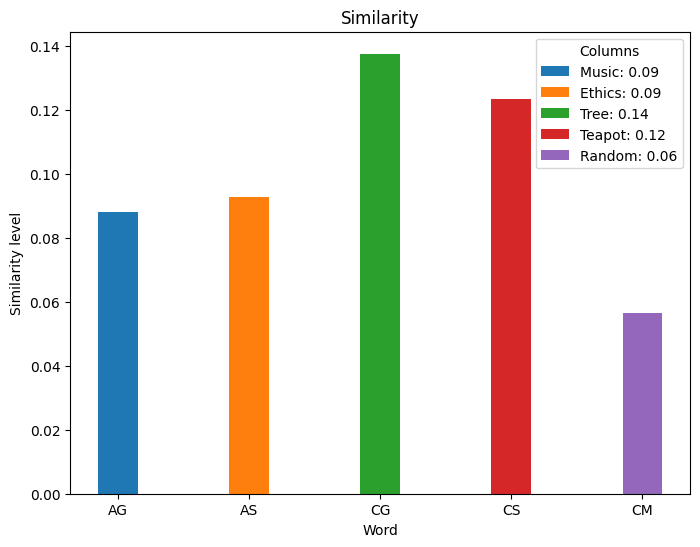

In [5]:

fig, ax = plt.subplots(figsize=(8, 6))

concepts = ['Music', 'Ethics', 'Tree', 'Teapot', 'Random']

for i, (col, val) in enumerate(similarity.items()):
    ax.bar(col, val, label=f'{concepts[i]}: {similarity[col]:.2f}', width=0.3)

ax.set_title('Similarity')
ax.set_xlabel('Word')
ax.set_ylabel('Similarity level')

ax.legend(title="Columns")


plt.show()

## Overlapping

In [6]:
results = []

for col in df.columns:
    defs = df[col].dropna().tolist()

    for i in range(len(defs)):
        for j in range(i + 1, len(defs)):
            score = overlap_coefficient(defs[i], defs[j])

            results.append({
                "column": col,
                "i": i,
                "j": j,
                "score": score
            })

synonym_df = pd.DataFrame(results)

In [7]:

synonym_df = synonym_df[synonym_df['score'] > 0.1].sort_values(by='score', ascending=False)
synonym_df

,column,i,j,score
950,CG,12,15,0.857143
960,CG,12,25,0.857143
847,CG,6,11,0.833333
848,CG,6,12,0.833333
851,CG,6,15,0.833333
...,...,...,...,...
340,AG,21,26,0.111111
552,AS,9,13,0.111111
618,AS,13,21,0.111111
620,AS,13,23,0.111111


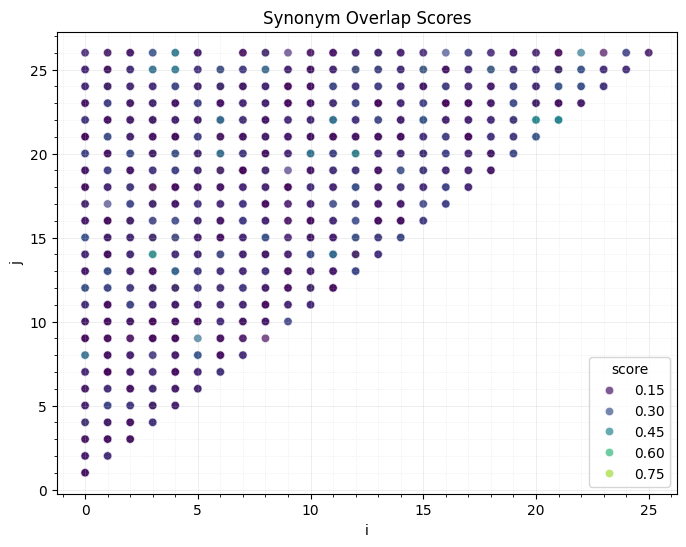

In [8]:
data = synonym_df[synonym_df['i'] < synonym_df['j']]            # is considered just one pair of (x,y)

plt.figure(figsize=(8,6))

ax = sns.scatterplot(
    data=data,
    x='i',
    y='j',
    hue='score',
    palette='viridis',
    alpha=0.7
)

ax.grid(True, which='major', linestyle='-', linewidth=0.5, alpha=0.3)

ax.xaxis.set_minor_locator(AutoMinorLocator(5))
ax.yaxis.set_minor_locator(AutoMinorLocator(5))

ax.grid(True, which='minor', linestyle=':', linewidth=0.5, alpha=0.3)

plt.title("Synonym Overlap Scores")
plt.show()

In [9]:
print(f"Percentage of pairs with score > 0.5: {len(synonym_df[synonym_df['score'] > 0.5]) / len(synonym_df) * 100:.2f}%")

Percentage of pairs with score > 0.5: 6.58%


# SIMLEX - SIMSEM


## Common words

In [10]:
stopwords = [
    "a", "an", "the",
    "and", "or", "but", "if", "because",
    "as", "until", "while",
    "of", "at", "by", "for", "with",
    "about", "against", "between",
    "into", "through", "during",
    "before", "after", "above", "below",
    "to", "from", "up", "down", "in", "out", "on", "off", "over", "under",
    "again", "further", "then", "once",
    "here", "there", "when", "where", "why", "how",
    "all", "any", "both", "each", "few", "more", "most", "other", "some", "such",
    "no", "nor", "not", "only", "own", "same", "so", "than", "too", "very",
    "s", "t", "can", "will", "just", "don", "should", "now"
]

def get_column_counts(column):
    words = ' '.join(column.dropna().astype(str)).lower().split()

    word_dict = {}

    for word in words:
        if word not in stopwords:
            word_dict[word] = word_dict.get(word, 0) + 1

    return word_dict

counts_per_column = [get_column_counts(df[col]) for col in df.columns]


for i, counts in enumerate(counts_per_column):
    sorted_counts = sorted(counts.items(), key=lambda x: x[1], reverse=True)
    print(f"Column {df.columns[i]} - most frequent words: {sorted_counts[:5]}\n")


Column AG - most frequent words: [('sounds', 15), ('that', 8), ('be', 7), ('instruments', 7), ('produced', 6)]

Column AS - most frequent words: [('that', 22), ('human', 12), ('is', 11), ('what', 10), ('right', 9)]

Column CG - most frequent words: [('plant', 18), ('branches', 14), ('leaves', 14), ('it', 10), ('that', 10)]

Column CS - most frequent words: [('used', 25), ('tea', 13), ('container', 13), ('usually', 10), ('is', 8)]

Column CM - most frequent words: [('that', 7), ('used', 7), ('is', 6), ('it', 5), ('has', 4)]



## Lemmatization

In [11]:
from nltk.stem import WordNetLemmatizer
lemmatizer = WordNetLemmatizer()

In [12]:
definitions = {}

for col in df.columns:
    definitions[col] = []

    for defn in df[col]:
        if pd.isna(defn):
            definitions[col].append(None)
            continue

        def_set = {
            lemmatizer.lemmatize(word)
            for word in re.findall(r'\b\w+\b', defn.lower())
            if word not in stopwords
        }

        definitions[col].append(def_set)

simlex_df = pd.DataFrame(definitions)
simlex_df

,AG,AS,CG,CS,CM
0,"{instrument, sound, various, it, also, produce...","{thought, it, explaining, period, context, ide...","{foliage, branch, used, root, trunk, produce, ...","{infuse, made, tea, boiling, ceramic, water, u...","{generated, community, discomfort, embarrassin..."
1,"{instrument, sound, people, simultaneously, se...","{philosophy, branch, defining, focus, behavior...","{branch, different, type, size, having, root, ...","{usually, used, liquid, container, heating, me...","{result, mental, abstract, thinking, activity,..."
2,"{group, perceived, system, visual, existing, a...","{his, being, quality, act, according, common, ...","{kind, foliage, anchored, that, ha, ground, it...","{decant, infuse, cup, small, hot, it, let, tea...","{story, storydriven, wich, like, human, device..."
3,"{instrument, sound, one, musical, created}","{philosophy, are, considered, behavior, scienc...","{being, branch, characterized, flower, fruit, ...","{make, tea, used, tool}","{which, discomfort, different, be, one, is, li..."
4,"{keyboard, instrument, orchestral, sound, it, ...","{prohibited, action, it, every, itself, partic...","{branch, leaf, plant, made, tunk}","{which, ha, recipient, shape, tea, pot, contai...",None
5,"{instrument, sound, be, specific, voice, organ...","{philosophy, human, study, right, society, wha...","{nutriment, fruit, these, usually, give, that,...","{tea, be, used, store, liquid, container, pour...","{nutriment, photosynthesis, branch, give, frui..."
6,"{being, aim, sound, emotion, triggering, seque...","{philosophy, branch, aim, certain, right, are,...","{plant, branch, woody, leaf}","{which, often, tea, ceramic, infusion, contain...","{ha, engineering, system, capturing, distribut..."
7,"{sound, capable, emotion, arousing, sequence, ...","{which, that, principle, right, society, learn...","{branch, type, root, trunk, leaf, composed, pl...","{normally, setting, tea, also, ceramic, water,...","{various, ability, japanese, dish, rice, add, ..."
8,"{harmony, sound, heard, are, set, that}","{conventionally, rule, set, unwritten, shared}","{seed, branch, organic, root, trunk, born, lea...","{holding, useful, container, pouring, tee}","{lens, improve, used, use, object, vision, gra..."
9,"{which, danger, loss, possibility, condition, ...","{strategy, people, possible, help, decision, p...","{perform, especially, practical, something, us...","{microscope, instrument, that, seen, wicth, na...","{instrument, especially, travel, unfamiliar, i..."


In [13]:
similarity_jaccard = {}
similarity_overlap = {}
simlex_dict = {}

for col in simlex_df.columns:
    jaccard_vals = []
    overlap_vals = []

    defs = simlex_df[col].dropna().tolist()

    for i in range(len(defs)):
        for j in range(i + 1, len(defs)):
            jaccard_vals.append(jaccard_similarity(defs[i], defs[j]))
            overlap_vals.append(overlap_coefficient(defs[i], defs[j]))
            simlex_dict[(col, i, j)] = jaccard_similarity(defs[i], defs[j])

    similarity_jaccard[col] = sum(jaccard_vals) / len(jaccard_vals) if jaccard_vals else 0
    similarity_overlap[col] = sum(overlap_vals) / len(overlap_vals) if overlap_vals else 0
    

print(f"Jaccard: {similarity_jaccard} \nOverlap: {similarity_overlap}")

Jaccard: {'AG': 0.08502837675723296, 'AS': 0.08528133136141923, 'CG': 0.16116207279711237, 'CS': 0.13850758193042872, 'CM': 0.011860189335329578} 
Overlap: {'AG': 0.21828468023792308, 'AS': 0.18617447367447368, 'CG': 0.3884385558196783, 'CS': 0.3039968383105638, 'CM': 0.03248120255812564}


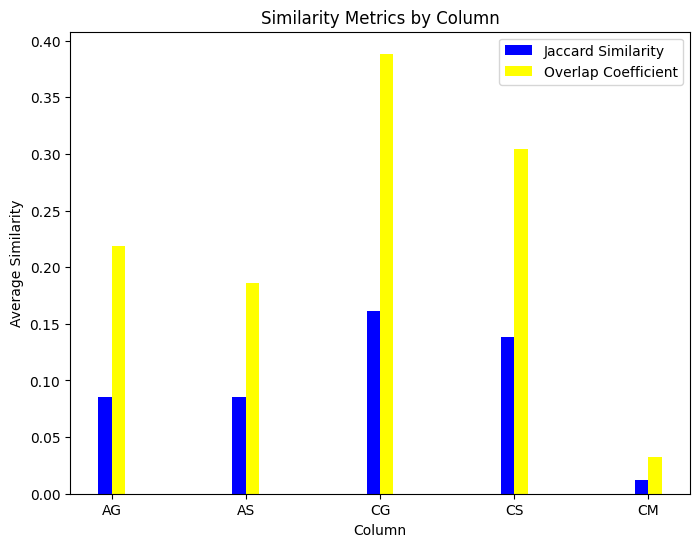

In [14]:
bar_width = 0.10
positions = np.arange(len(similarity_jaccard))

fig, ax = plt.subplots(figsize=(8, 6))
ax.bar(positions - bar_width/2, list(similarity_jaccard.values()), width=bar_width, label='Jaccard Similarity', color='blue')
ax.bar(positions + bar_width/2, list(similarity_overlap.values()), width=bar_width, label='Overlap Coefficient', color='yellow')

ax.set_xticks(positions)
ax.set_xticklabels(similarity_jaccard.keys())

ax.set_title('Similarity Metrics by Column')
ax.set_xlabel('Column')
ax.set_ylabel('Average Similarity')
ax.legend()
plt.show()


These results indicate a generally low level of lexical overlap across the sets of definitions for the five concepts (AG, AS, CG, CS, CM), suggesting that the participants tend to use relatively diverse vocabulary when defining each category.

The Jaccard similarity scores are consistently low in all cases, ranging from about 0.012 (CM) to 0.161 (CG), which reflects the proportion of exact shared words between definitions and highlights minimal strict lexical overlap.

In contrast, the overlap coefficient values are higher across all categories (from 0.032 to 0.388), since this metric captures partial inclusion of smaller word sets within larger ones, rather than requiring full symmetry. The CG category shows the highest consistency in both measures, indicating that its definitions share more common terms and are therefore more lexically aligned. Conversely, CM exhibits the lowest similarity values, suggesting a highly heterogeneous and less uniform set of definitions. Overall, the gap between Jaccard and overlap confirms that while exact word agreement is limited, some partial sharing of vocabulary still exists, especially in more structured or concrete categories.


## Simsem

## Vector rappresentation

In [15]:
cosine_dict = {}

for col in simlex_df.columns:
    defs = simlex_df[col].dropna().tolist()
    for i in range(len(defs)):
        for j in range(i + 1, len(defs)):
            ph1 = " ".join(defs[i])
            ph2 = " ".join(defs[j])
            def_1 = model.encode(ph1)
            def_2 = model.encode(ph2)

            cosine_dict[(col, i, j)] = cosine_similarity([def_1], [def_2])[0][0]

In [16]:
greater_cosine_dict = {}
simsem_dict = {}

for pair in cosine_dict:
    if cosine_dict[pair] > 0.8:
        greater_cosine_dict[pair] = cosine_dict[pair]


print(f"Percentage of pairs with cosine similarity > 0.8: {len(greater_cosine_dict) / len(cosine_dict) * 100:.2f}% \nTotal pairs: {len(cosine_dict)} \nGreater cosine: {len(greater_cosine_dict)}")

# greater_cosine_dict
for pair in greater_cosine_dict:
    print(f"{pair}: {greater_cosine_dict[pair]:.4f}, \n{df.loc[pair[1], pair[0]]} \n{df.loc[pair[2], pair[0]]}\n")



Percentage of pairs with cosine similarity > 0.8: 0.52% 
Total pairs: 1729 
Greater cosine: 9
('AS', 22, 24): 0.8109, 
branch of philosophy that studies human behavior, and in particular analyzes what is right or wrong, and what collective behaviors lead to good or evil. 
branch of philosophy that studies human behavior by trying to define what is right and what is wrong.

('CG', 1, 24): 0.8581, 
plant, with different types and generic size, having leaves, branches, roots. 
plant of generic dimensions, composed of branches, roots and leaves

('CG', 6, 12): 0.8311, 
woody plant with branches and leaves 
plant with a woody trunk and leaves

('CG', 7, 14): 0.9210, 
type of plant composed of roots, trunk, branches and leaves. 
plant with roots, branches, trunk and leaves

('CG', 7, 15): 0.8089, 
type of plant composed of roots, trunk, branches and leaves. 
complex terrestrial plant characterized by a woody trunk and apical branches on which leaves grow

('CG', 7, 24): 0.8354, 
type of plan

In [17]:
records = []
all_keys = set(simlex_dict.keys()) & set(cosine_dict.keys()) # consider just pairs for which we have both metrics

for (col, i, j) in all_keys:
    concrete = "abstract" if col in ["AG", "AS"] else "concrete"
    specific = "generic" if col in ["AG", "CG"] else "specific"
    records.append({
        "word": col,
        "i": i,
        "j": j,
        "simlex": simlex_dict[(col, i, j)],
        "simsem": cosine_dict[(col, i, j)],
        "concretness": concrete,
        "specificity": specific,
        "def1": df.loc[i, col],
        "def2": df.loc[j, col]
    })

pairs_df = pd.DataFrame(records)
pairs_df.head()

,word,i,j,simlex,simsem,concretness,specificity,def1,def2
0,AS,1,24,0.31250,0.646946,abstract,specific,branch of philosophy that focuses on defining ...,branch of philosophy that studies human behavi...
1,CM,6,16,0.00000,0.008032,concrete,specific,engineering system that has the purpose of cap...,"pathological addiction, there are dedicated pl..."
2,AG,6,25,0.12500,0.373144,abstract,generic,sequence of sounds with the aim of triggering ...,a set of sounds.
3,CM,9,21,0.00000,-0.099159,concrete,specific,it is an instrument used to identify direction...,point of interaction with a more or less compl...
4,CG,9,11,0.02439,0.179008,concrete,generic,a tool is an object used to perform practical ...,a usually thick and tall (depending on the reg...


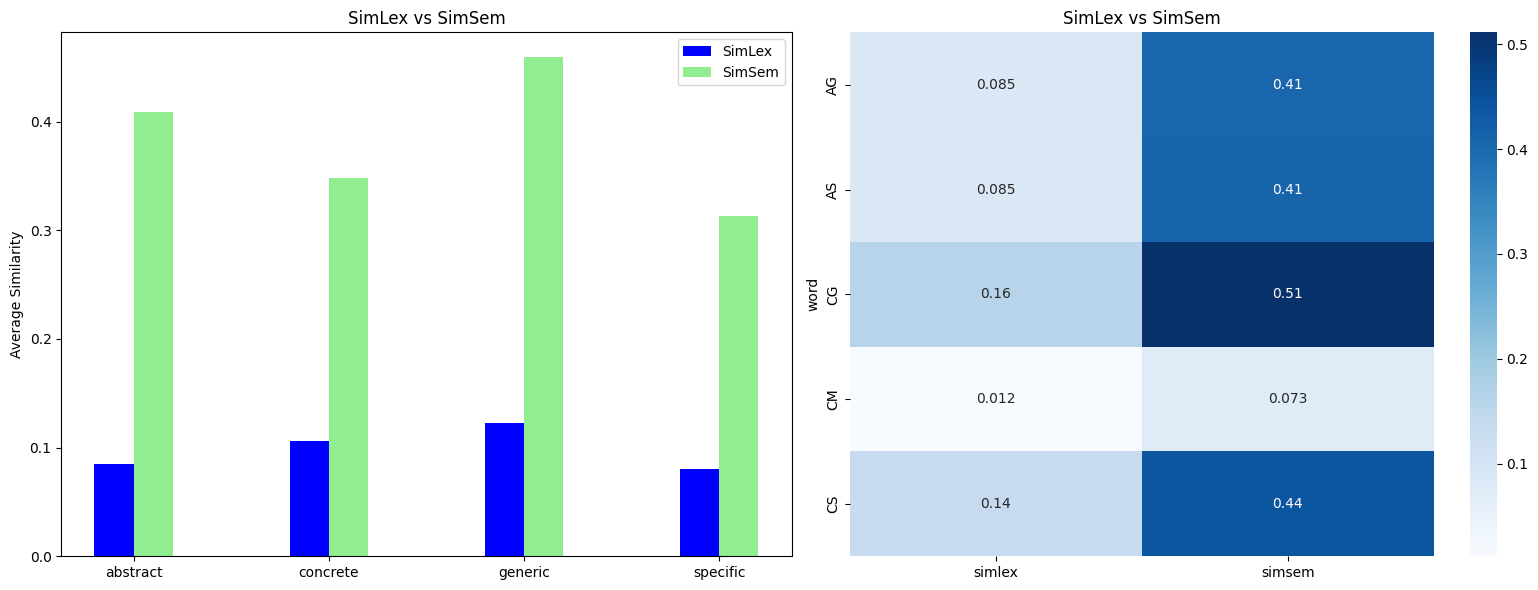

In [18]:
agg_concretezza = (
    pairs_df
    .groupby("concretness")[["simlex", "simsem"]]
    .mean()
    .reset_index()
)

agg_specificita = (
    pairs_df
    .groupby("specificity")[["simlex", "simsem"]]
    .mean()
    .reset_index()
)

agg_4_gruppi = (
    pairs_df
    .groupby("word")[["simlex", "simsem"]]
    .mean()
    .reset_index()
)

df_heat = agg_4_gruppi.set_index("word")

fig, ax = plt.subplots(1, 2, figsize=(16, 6))

# BAR PLOT

cats = list(agg_concretezza["concretness"]) + list(agg_specificita["specificity"])
simlex_vals = list(agg_concretezza["simlex"]) + list(agg_specificita["simlex"])
simsem_vals = list(agg_concretezza["simsem"]) + list(agg_specificita["simsem"])

x_pos = np.arange(len(cats))
width = 0.2

ax[0].bar(x_pos - width/2, simlex_vals, width, label="SimLex", color="blue")
ax[0].bar(x_pos + width/2, simsem_vals, width, label="SimSem", color="lightgreen")

ax[0].set_xticks(x_pos)
ax[0].set_xticklabels(cats)
ax[0].set_ylabel("Average Similarity")
ax[0].set_title("SimLex vs SimSem")
ax[0].legend()

# HEATMAP

df_heat = agg_4_gruppi.set_index("word")

sns.heatmap(df_heat, annot=True, cmap="Blues", ax=ax[1])
ax[1].set_title("SimLex vs SimSem")

plt.tight_layout()
plt.show()

From the two plots, it emerges that semantic similarity (SimSem) is consistently higher than lexical similarity (SimLex) across all categories considered, even though the words used in the definitions are often different, the overall meaning remains very close.
SimLex values are generally low, indicating little lexical overlap between the definitions, whereas SimSem shows higher values, suggesting that the content is semantically similar. 
The “generic” categories tend to exhibit higher similarity than the “specific” ones, while differences across combinations of concreteness and abstraction are more subtle and less pronounced. 
Overall, semantic similarity better captures the fact that two sentences can express the same concept even when using different words, whereas lexical similarity tends to underestimate this closeness.
